In [ ]:
import pandas as pd
import numpy as np

# So we are able to see all columns
pd.set_option('display.max_rows', 2000)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
files = os.listdir(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics"
)
files

['sampled_all_systems.csv',
 'concat_flaml.csv',
 'concat_ag.csv',
 'result_monotonic_llama.csv',
 'result_monotonic_mistral.csv',
 'llama.csv',
 'mistral.csv',
 'result_equal_monotonic_ag_equal.csv',
 'result_monotonic_ag_equal.csv',
 'result_equal_monotonic_flaml_equal.csv',
 'result_monotonic_flaml_equal.csv',
 'result_equal_monotonic_rf_equal.csv',
 'result_monotonic_rf_equal.csv',
 'old_concat_rf.csv',
 'old_hpo_all_systems.csv',
 'concat_rf.csv',
 'hpo_all_systems.csv']

In [ ]:
# This is to simply obtain the dataset's type (multi or bin)
dataset_and_type = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/results_100_stratified.csv",
    sep=";"
)
dataset_and_type = dataset_and_type.loc[:, ["dataset"]]
dataset_and_type = dataset_and_type.drop_duplicates(subset=["dataset"], ignore_index=True)
dataset_and_type["pure_dataset"] = dataset_and_type["dataset"].str[:5]
dataset_and_type

,dataset,pure_dataset
0,ed_01_multi,ed_01
1,ed_02_multi,ed_02
2,ed_03_multi,ed_03
3,ed_04_multi,ed_04
4,ed_05_multi,ed_05
5,fn_01_multi,fn_01
6,fn_02_bin,fn_02
7,fn_03_multi,fn_03
8,fn_04_multi,fn_04
9,fn_05_multi,fn_05


# FLAML

In [ ]:
system = "flaml"
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

## HPO

In [ ]:
hpo = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)
hpo = hpo[hpo["automl_system"] == system_map[system]]
hpo = hpo.merge(
    dataset_and_type,
    left_on="trained_dataset",
    right_on="pure_dataset",
)
hpo = hpo.rename(
    columns={
        "trained_dataset": "pure_trained_dataset",
        "dataset": "trained_dataset",
    }
)
hpo = hpo.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
hpo = hpo.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)
hpo = hpo.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
hpo["predicted_type"] = "bin"
multi_mask = hpo["predicted_dataset"].str.contains("multi")
hpo.loc[multi_mask, "predicted_type"] = "multi"

hpo["are_concat_pred_equal"] = hpo.apply(
    lambda row: row["trained_dataset"] == row["predicted_dataset"],
    axis=1
)
equal_hpo = hpo[hpo["are_concat_pred_equal"]]
diff_hpo = hpo[~(hpo["are_concat_pred_equal"])]
hpo

,pure_trained_dataset,pure_predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,are_concat_pred_equal
0,pc_02,pc_01,FLAML,gmm_random,100,[],[],False,0.501181,0.706188,"['negative', 'positive']","['negative', 'positive']",pc_02_bin,pc_02,pc_01_bin,pc_01,pc,bin,False
1,pc_02,pc_03,FLAML,gmm_random,100,[],[],False,0.501573,0.731290,"['negative', 'positive']","['negative', 'positive']",pc_02_bin,pc_02,pc_03_bin,pc_03,pc,bin,False
2,pc_02,pc_04,FLAML,gmm_random,100,[],[],False,0.500481,0.777217,"['negative', 'positive']","['negative', 'positive']",pc_02_bin,pc_02,pc_04_bin,pc_04,pc,bin,False
3,pc_02,pc_06,FLAML,gmm_random,100,[],[],False,0.500622,0.825439,"['negative', 'positive']","['negative', 'positive']",pc_02_bin,pc_02,pc_06_bin,pc_06,pc,bin,False
4,pc_02,pc_02,FLAML,gmm_random,100,[],[],False,0.501416,0.796034,"['negative', 'positive']","['negative', 'positive']",pc_02_bin,pc_02,pc_02_bin,pc_02,pc,bin,True
5,ed_03,ed_01,FLAML,gmm_random,100,"['joy', 'anger', 'disgust', 'fear', 'sadness',...","['neutral', 'admiration', 'curiosity']",False,0.307054,0.000000,"['joy', 'anger', 'disgust', 'fear', 'sadness',...","['neutral', 'admiration', 'curiosity']",ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,False
6,ed_03,ed_02,FLAML,gmm_random,100,[],"['gratitude', 'desire', 'embarrassment', 'admi...",False,0.342871,0.031118,"['joy', 'anger', 'fear', 'love', 'sadness', 's...","['gratitude', 'disapproval', 'remorse', 'fear'...",ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,False
7,ed_03,ed_03,FLAML,gmm_random,100,"['embarrassment', 'relief', 'pride', 'nervousn...",[],False,0.294867,0.381555,"['gratitude', 'grief', 'disapproval', 'remorse...","['gratitude', 'grief', 'disapproval', 'remorse...",ed_03_multi,ed_03,ed_03_multi,ed_03,ed,multi,True
8,fn_01,fn_02,FLAML,gmm_random,100,[],"['mostly_true', 'half_true', 'pants_on_fire', ...",False,0.520833,0.145833,"['false', 'true']","['mostly_true', 'half_true', 'true', 'barely_t...",fn_01_multi,fn_01,fn_02_bin,fn_02,fn,bin,False
9,fn_01,fn_06,FLAML,gmm_random,100,['true'],"['mostly_true', 'half_true', 'pants_on_fire', ...",False,0.535865,0.088608,"['false', 'true']","['mostly_true', 'half_true', 'barely_true', 'f...",fn_01_multi,fn_01,fn_06_bin,fn_06,fn,bin,False


## Concat

In [ ]:
automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_{system}.csv",
    sep=";"
)
automl_concat_df = automl_concat_df.merge(
    dataset_and_type,
    left_on="trained_dataset",
    right_on="pure_dataset",
)
automl_concat_df = automl_concat_df.rename(
    columns={
        "trained_dataset": "pure_trained_dataset",
        "dataset": "trained_dataset",
    }
)
automl_concat_df = automl_concat_df.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
automl_concat_df = automl_concat_df.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)

automl_concat_df = automl_concat_df.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
automl_concat_df["predicted_type"] = "bin"
multi_mask = automl_concat_df["predicted_dataset"].str.contains("multi")
automl_concat_df.loc[multi_mask, "predicted_type"] = "multi"

automl_concat_df["trained_type"] = "bin"
multi_mask = automl_concat_df["trained_dataset"].str.contains("multi")
automl_concat_df.loc[multi_mask, "trained_type"] = "multi"

adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["pure_predicted_dataset"]
aug_mask = automl_concat_df["pure_trained_dataset"] == automl_concat_df["pure_predicted_dataset"]

equal_concat_df = automl_concat_df.loc[adapt_mask & (~aug_mask)]
diff_concat_df = automl_concat_df.loc[(~adapt_mask) & (~aug_mask)]

automl_concat_df

,pure_trained_dataset,pure_predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,trained_type
0,hs_04,hs_04,hs_14,FLAML,gmm_random,25,[],[],False,0.906004,0.924859,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs_04_bin,hs_04,hs_04_bin,hs_04,hs,bin,bin
1,hs_04,hs_14,hs_14,FLAML,gmm_random,25,[],[],False,0.517544,0.600877,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs_04_bin,hs_04,hs_14_bin,hs_14,hs,bin,bin
2,hs_04,hs_04,hs_14,FLAML,gmm_random,50,[],[],False,0.906004,0.924761,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs_04_bin,hs_04,hs_04_bin,hs_04,hs,bin,bin
3,hs_04,hs_14,hs_14,FLAML,gmm_random,50,[],[],False,0.517544,0.605263,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs_04_bin,hs_04,hs_14_bin,hs_14,hs,bin,bin
4,hs_04,hs_04,hs_14,FLAML,gmm_random,75,[],[],False,0.906004,0.928077,"['toxic', 'not_toxic']","['toxic', 'not_toxic']",hs_04_bin,hs_04,hs_04_bin,hs_04,hs,bin,bin
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2035,pc_04,pc_01,pc_06,FLAML,gmm_random,75,[],[],False,0.501181,0.775154,"['negative', 'positive']","['negative', 'positive']",pc_04_bin,pc_04,pc_01_bin,pc_01,pc,bin,bin
2036,pc_04,pc_02,pc_06,FLAML,gmm_random,75,[],[],False,0.501416,0.798867,"['negative', 'positive']","['negative', 'positive']",pc_04_bin,pc_04,pc_02_bin,pc_02,pc,bin,bin
2037,pc_04,pc_03,pc_06,FLAML,gmm_random,75,[],[],False,0.501573,0.831653,"['negative', 'positive']","['negative', 'positive']",pc_04_bin,pc_04,pc_03_bin,pc_03,pc,bin,bin
2038,pc_04,pc_04,pc_06,FLAML,gmm_random,75,[],[],False,0.500481,0.875440,"['negative', 'positive']","['negative', 'positive']",pc_04_bin,pc_04,pc_04_bin,pc_04,pc,bin,bin


## 1. Evaluating Concat Equal

### 1.1 Frequency based on hold_out_f1_score

#### 1.1.1 System/Task/Percentage


In [ ]:
equal_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
FLAML          ed              25            0.276830
                               50            0.293362
                               75            0.283361
               fn              25            0.463778
                               50            0.462471
                               75            0.492299
               hs              25            0.707613
                               50            0.717594
                               75            0.741120
               pc              25            0.767735
                               50            0.771174
                               75            0.777310
               sd              25            0.384000
                               50            0.441333
                               75            0.481333
               ua              25            0.584437
                               50            0.600943
                               75            0.601538
Name: hold_out_f1_score, dtype: float64

#### 1.1.2 System/Task/Percentage/Type


In [ ]:
equal_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
FLAML          ed              25          multi             0.276830
                               50          multi             0.293362
                               75          multi             0.283361
               fn              25          bin               0.499200
                                           multi             0.375223
                               50          bin               0.486208
                                           multi             0.403128
                               75          bin               0.517185
                                           multi             0.430085
               hs              25          bin               0.728177
                                           multi             0.611651
                               50          bin               0.741505
                                           multi             0.606012
                               75          bin               0.761490
                                           multi             0.646061
               pc              25          bin               0.807840
                                           multi             0.589489
                               50          bin               0.810877
                                           multi             0.594719
                               75          bin               0.815549
                                           multi             0.607359
               sd              25          multi             0.384000
                               50          multi             0.441333
                               75          multi             0.481333
               ua              25          multi             0.584437
                               50          multi             0.600943
                               75          multi             0.601538
Name: hold_out_f1_score, dtype: float64

#### 1.1.3 System/Percentage/Type

In [ ]:
equal_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
FLAML          25          bin               0.739674
                           multi             0.550183
               50          bin               0.744350
                           multi             0.564459
               75          bin               0.757891
                           multi             0.575641
Name: hold_out_f1_score, dtype: float64

#### 1.1.4 Task/Percentage

In [ ]:
equal_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  percentage
ed              25            0.276830
                50            0.293362
                75            0.283361
fn              25            0.463778
                50            0.462471
                75            0.492299
hs              25            0.707613
                50            0.717594
                75            0.741120
pc              25            0.767735
                50            0.771174
                75            0.777310
sd              25            0.384000
                50            0.441333
                75            0.481333
ua              25            0.584437
                50            0.600943
                75            0.601538
Name: hold_out_f1_score, dtype: float64

#### 1.1.5 Percentage/Task/Type

In [ ]:
equal_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           25            0.276830
                                50            0.293362
                                75            0.283361
fn              bin             25            0.499200
                                50            0.486208
                                75            0.517185
                multi           25            0.375223
                                50            0.403128
                                75            0.430085
hs              bin             25            0.728177
                                50            0.741505
                                75            0.761490
                multi           25            0.611651
                                50            0.606012
                                75            0.646061
pc              bin             25            0.807840
                                50            0.810877
                                75            0.815549
                multi           25            0.589489
                                50            0.594719
                                75            0.607359
sd              multi           25            0.384000
                                50            0.441333
                                75            0.481333
ua              multi           25            0.584437
                                50            0.600943
                                75            0.601538
Name: hold_out_f1_score, dtype: float64

#### 1.1.6 Type

In [ ]:
equal_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.747305
multi,0.563428


#### 1.1.7 Percentage/Type

In [ ]:
equal_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_type  percentage
bin             25            0.739674
                50            0.744350
                75            0.757891
multi           25            0.550183
                50            0.564459
                75            0.575641
Name: hold_out_f1_score, dtype: float64

### 1.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    equal_concat_df
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        equal_concat_df,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,FLAML,ed_01_multi,gmm_random,75,0.045643
1,FLAML,ed_02_multi,gmm_random,50,0.557678
2,FLAML,fn_02_bin,gmm_random,25,0.576389
3,FLAML,fn_05_multi,gmm_random,75,0.477955
4,FLAML,fn_06_bin,gmm_random,75,0.561181
5,FLAML,fn_07_multi,gmm_random,50,0.409091
6,FLAML,fn_09_multi,gmm_random,75,0.369656
7,FLAML,fn_10_multi,gmm_random,75,0.475000
8,FLAML,hs_01_bin,gmm_random,50,0.807084
9,FLAML,hs_02_multi,gmm_random,75,0.824760


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        equal_concat_df
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            equal_concat_df,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
1,FLAML,ed_01_multi,gmm_random,50,0.029046,True
4,FLAML,ed_02_multi,gmm_random,50,0.557678,True
6,FLAML,fn_02_bin,gmm_random,25,0.576389,False
21,FLAML,fn_05_multi,gmm_random,25,0.451215,False
34,FLAML,fn_06_bin,gmm_random,50,0.544304,True
40,FLAML,fn_07_multi,gmm_random,50,0.409091,True
43,FLAML,fn_09_multi,gmm_random,50,0.338642,True
46,FLAML,fn_10_multi,gmm_random,50,0.450000,True
49,FLAML,hs_01_bin,gmm_random,50,0.807084,True
52,FLAML,hs_02_multi,gmm_random,50,0.811800,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,fn_02_bin,gmm_random,25,0.576389,False
1,FLAML,fn_05_multi,gmm_random,25,0.451215,False
2,FLAML,hs_03_bin,gmm_random,25,0.758403,False
3,FLAML,hs_06_bin,gmm_random,25,0.598588,False
4,FLAML,hs_10_bin,gmm_random,25,0.736667,False
5,FLAML,hs_12_bin,gmm_random,25,0.689189,False
6,FLAML,hs_13_multi,gmm_random,25,0.757106,False
7,FLAML,pc_01_bin,gmm_random,25,0.773264,False
8,FLAML,pc_04_bin,gmm_random,25,0.875954,False
9,FLAML,pc_07_multi,gmm_random,25,0.775720,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,fn_02_bin,gmm_random,25,0.576389,False
1,FLAML,fn_05_multi,gmm_random,25,0.451215,False
2,FLAML,hs_03_bin,gmm_random,25,0.758403,False
3,FLAML,hs_06_bin,gmm_random,25,0.598588,False
4,FLAML,hs_10_bin,gmm_random,25,0.736667,False
5,FLAML,hs_12_bin,gmm_random,25,0.689189,False
6,FLAML,hs_13_multi,gmm_random,25,0.757106,False
7,FLAML,pc_01_bin,gmm_random,25,0.773264,False
8,FLAML,pc_04_bin,gmm_random,25,0.875954,False
9,FLAML,pc_07_multi,gmm_random,25,0.775720,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,fn_02_bin,gmm_random,25,0.576389,False
1,FLAML,fn_05_multi,gmm_random,25,0.451215,False
2,FLAML,hs_03_bin,gmm_random,25,0.758403,False
3,FLAML,hs_06_bin,gmm_random,25,0.598588,False
4,FLAML,hs_10_bin,gmm_random,25,0.736667,False
5,FLAML,hs_12_bin,gmm_random,25,0.689189,False
6,FLAML,hs_13_multi,gmm_random,25,0.757106,False
7,FLAML,pc_01_bin,gmm_random,25,0.773264,False
8,FLAML,pc_04_bin,gmm_random,25,0.875954,False
9,FLAML,pc_07_multi,gmm_random,25,0.775720,False


### 1.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 1.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-3951610294.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.550028
"(0.05, 0.1]",0.682971
"(0.1, 0.2]",0.680457
"(0.2, 0.3]",0.724843
"(0.3, 0.5]",0.511898
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.434667
"(0.7, 0.8]",0.733496
"(0.8, 0.9]",0.583768


#### 1.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-1533895566.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.284517
               fn             0.496762
               hs             0.676965
               ua             0.577018
(0.05, 0.1]    hs             0.621241
               pc             0.729269
(0.1, 0.2]     hs             0.700292
               pc             0.748099
               ua             0.606085
(0.2, 0.3]     fn             0.336686
               hs             0.923244
               pc             0.751951
(0.3, 0.5]     fn             0.454388
               hs             0.741935
(0.6, 0.7]     sd             0.434667
(0.7, 0.8]     hs             0.733496
(0.8, 0.9]     fn             0.513889
               hs             0.800970
               sd             0.436444
(0.9, 1.0]     fn             0.485595
               hs             0.767153
               pc             0.813019
               ua             0.598933

## 2. Evaluating Concat Diff

### 2.1 Frequency based on hold_out_f1_score

#### 2.1.1 System/Task/Percentage


In [ ]:
diff_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
FLAML          ed              25            0.005179
                               50            0.021457
                               75            0.038457
               fn              25            0.437830
                               50            0.430017
                               75            0.435599
               hs              25            0.633989
                               50            0.643710
                               75            0.639850
               pc              25            0.587166
                               50            0.587800
                               75            0.594632
               ua              25            0.479873
                               50            0.478418
                               75            0.477809
Name: hold_out_f1_score, dtype: float64

#### 2.1.2 System/Task/Percentage/Type


In [ ]:
diff_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
FLAML          ed              25          multi             0.005179
                               50          multi             0.021457
                               75          multi             0.038457
               fn              25          bin               0.437830
                               50          bin               0.430017
                               75          bin               0.435599
               hs              25          bin               0.646328
                                           multi             0.350192
                               50          bin               0.656349
                                           multi             0.353008
                               75          bin               0.653487
                                           multi             0.326191
               pc              25          bin               0.642333
                                           multi             0.408115
                               50          bin               0.644839
                                           multi             0.402672
                               75          bin               0.654375
                                           multi             0.400728
               ua              25          multi             0.479873
                               50          multi             0.478418
                               75          multi             0.477809
Name: hold_out_f1_score, dtype: float64

#### 2.1.3 System/Percentage/Type

In [ ]:
diff_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
FLAML          25          bin               0.637882
                           multi             0.441004
               50          bin               0.642524
                           multi             0.438326
               75          bin               0.647947
                           multi             0.436699
Name: hold_out_f1_score, dtype: float64

#### 2.1.4 Task/Percentage

In [ ]:
diff_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  percentage
ed              25            0.005179
                50            0.021457
                75            0.038457
fn              25            0.437830
                50            0.430017
                75            0.435599
hs              25            0.633989
                50            0.643710
                75            0.639850
pc              25            0.587166
                50            0.587800
                75            0.594632
ua              25            0.479873
                50            0.478418
                75            0.477809
Name: hold_out_f1_score, dtype: float64

#### 2.1.5 Percentage/Task/Type

In [ ]:
diff_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           25            0.005179
                                50            0.021457
                                75            0.038457
fn              bin             25            0.437830
                                50            0.430017
                                75            0.435599
hs              bin             25            0.646328
                                50            0.656349
                                75            0.653487
                multi           25            0.350192
                                50            0.353008
                                75            0.326191
pc              bin             25            0.642333
                                50            0.644839
                                75            0.654375
                multi           25            0.408115
                                50            0.402672
                                75            0.400728
ua              multi           25            0.479873
                                50            0.478418
                                75            0.477809
Name: hold_out_f1_score, dtype: float64

#### 2.1.6 Type

In [ ]:
diff_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.642785
multi,0.438676


#### 2.1.7 Percentage/Type

In [ ]:
diff_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_type  percentage
bin             25            0.637882
                50            0.642524
                75            0.647947
multi           25            0.441004
                50            0.438326
                75            0.436699
Name: hold_out_f1_score, dtype: float64

### 2.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    diff_concat_df
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        diff_concat_df,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,FLAML,ed_01_multi,gmm_random,75,0.062241
1,FLAML,ed_02_multi,gmm_random,50,0.018017
2,FLAML,fn_02_bin,gmm_random,25,0.520833
3,FLAML,fn_06_bin,gmm_random,75,0.502110
4,FLAML,hs_02_multi,gmm_random,50,0.567571
5,FLAML,hs_03_bin,gmm_random,50,0.653361
6,FLAML,hs_06_bin,gmm_random,50,0.611952
7,FLAML,hs_08_bin,gmm_random,25,0.930549
8,FLAML,hs_09_bin,gmm_random,25,0.911147
9,FLAML,hs_10_bin,gmm_random,25,0.713333


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        diff_concat_df
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            diff_concat_df,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
1,FLAML,ed_01_multi,gmm_random,50,0.024896,True
4,FLAML,ed_02_multi,gmm_random,50,0.018017,True
15,FLAML,fn_02_bin,gmm_random,25,0.520833,False
28,FLAML,fn_06_bin,gmm_random,50,0.485232,True
34,FLAML,hs_02_multi,gmm_random,50,0.567571,True
58,FLAML,hs_03_bin,gmm_random,50,0.653361,True
94,FLAML,hs_06_bin,gmm_random,50,0.611952,True
138,FLAML,hs_08_bin,gmm_random,25,0.930549,False
204,FLAML,hs_09_bin,gmm_random,25,0.911147,False
261,FLAML,hs_10_bin,gmm_random,25,0.713333,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,fn_02_bin,gmm_random,25,0.520833,False
1,FLAML,hs_08_bin,gmm_random,25,0.930549,False
2,FLAML,hs_09_bin,gmm_random,25,0.911147,False
3,FLAML,hs_10_bin,gmm_random,25,0.713333,False
4,FLAML,hs_12_bin,gmm_random,25,0.540541,False
5,FLAML,hs_13_multi,gmm_random,25,0.648579,False
6,FLAML,pc_01_bin,gmm_random,25,0.774681,False
7,FLAML,pc_03_bin,gmm_random,25,0.833347,False
8,FLAML,pc_04_bin,gmm_random,25,0.836101,False
9,FLAML,pc_05_multi,gmm_random,25,0.524872,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,fn_02_bin,gmm_random,25,0.520833,False
1,FLAML,hs_08_bin,gmm_random,25,0.930549,False
2,FLAML,hs_09_bin,gmm_random,25,0.911147,False
3,FLAML,hs_10_bin,gmm_random,25,0.713333,False
4,FLAML,hs_12_bin,gmm_random,25,0.540541,False
5,FLAML,hs_13_multi,gmm_random,25,0.648579,False
6,FLAML,pc_01_bin,gmm_random,25,0.774681,False
7,FLAML,pc_03_bin,gmm_random,25,0.833347,False
8,FLAML,pc_04_bin,gmm_random,25,0.836101,False
9,FLAML,pc_05_multi,gmm_random,25,0.524872,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,fn_02_bin,gmm_random,25,0.520833,False
1,FLAML,hs_08_bin,gmm_random,25,0.930549,False
2,FLAML,hs_09_bin,gmm_random,25,0.911147,False
3,FLAML,hs_10_bin,gmm_random,25,0.713333,False
4,FLAML,hs_12_bin,gmm_random,25,0.540541,False
5,FLAML,hs_13_multi,gmm_random,25,0.648579,False
6,FLAML,pc_01_bin,gmm_random,25,0.774681,False
7,FLAML,pc_03_bin,gmm_random,25,0.833347,False
8,FLAML,pc_04_bin,gmm_random,25,0.836101,False
9,FLAML,pc_05_multi,gmm_random,25,0.524872,False


### 2.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 2.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-3871234073.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.499071
"(0.05, 0.1]",0.478366
"(0.1, 0.2]",0.523522
"(0.2, 0.3]",0.550048
"(0.3, 0.5]",0.386545
"(0.5, 0.6]",NaN
"(0.6, 0.7]",NaN
"(0.7, 0.8]",0.661457
"(0.8, 0.9]",NaN


#### 2.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3687020511.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.021698
               fn             0.450461
               hs             0.611708
               ua             0.457141
(0.05, 0.1]    hs             0.343131
               pc             0.488025
(0.1, 0.2]     pc             0.538936
               ua             0.494094
(0.2, 0.3]     pc             0.550048
(0.3, 0.5]     fn             0.386545
(0.7, 0.8]     hs             0.661457
(0.9, 1.0]     hs             0.664706
               pc             0.784090
               ua             0.465372

## 3. Evaluating HPO Equal

### 3.1 Frequency based on hold_out_f1_score

#### 3.1.1 System/Task/Percentage


In [ ]:
equal_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
FLAML          ed              100           0.536479
               fn              100           0.483421
               hs              100           0.783317
               pc              100           0.739248
               sd              100           0.676994
               ua              100           0.548529
Name: hold_out_f1_score, dtype: float64

#### 3.1.2 System/Task/Percentage/Type


In [ ]:
equal_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
FLAML          ed              100         multi             0.536479
               fn              100         bin               0.521888
                                           multi             0.473804
               hs              100         bin               0.778299
                                           multi             0.797119
               pc              100         bin               0.822393
                                           multi             0.635316
               sd              100         bin               0.828125
                                           multi             0.626617
               ua              100         multi             0.548529
Name: hold_out_f1_score, dtype: float64

#### 3.1.3 System/Percentage/Type

In [ ]:
equal_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
FLAML          100         bin               0.765534
                           multi             0.579120
Name: hold_out_f1_score, dtype: float64

#### 3.1.4 Task/Percentage

In [ ]:
equal_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_task,percentage,
ed,100,0.536479
fn,100,0.483421
hs,100,0.783317
pc,100,0.739248
sd,100,0.676994
ua,100,0.548529


#### 3.1.5 Percentage/Task/Type

In [ ]:
equal_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           100           0.536479
fn              bin             100           0.521888
                multi           100           0.473804
hs              bin             100           0.778299
                multi           100           0.797119
pc              bin             100           0.822393
                multi           100           0.635316
sd              bin             100           0.828125
                multi           100           0.626617
ua              multi           100           0.548529
Name: hold_out_f1_score, dtype: float64

#### 3.1.6 Type

In [ ]:
equal_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.765534
multi,0.579120


#### 3.1.7 Percentage/Type

In [ ]:
equal_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_type,percentage,
bin,100,0.765534
multi,100,0.579120


### 3.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    equal_hpo
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        equal_hpo,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,FLAML,ed_01_multi,gmm_random,100,0.439834
1,FLAML,ed_02_multi,gmm_random,100,0.553599
2,FLAML,ed_03_multi,gmm_random,100,0.381555
3,FLAML,ed_04_multi,gmm_random,100,0.915740
4,FLAML,ed_05_multi,gmm_random,100,0.391667
5,FLAML,fn_01_multi,gmm_random,100,0.236852
6,FLAML,fn_02_bin,gmm_random,100,0.541667
7,FLAML,fn_03_multi,gmm_random,100,0.225308
8,FLAML,fn_04_multi,gmm_random,100,0.563565
9,FLAML,fn_05_multi,gmm_random,100,0.470249


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        equal_hpo
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            equal_hpo,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,ed_01_multi,gmm_random,100,0.439834,True
1,FLAML,ed_02_multi,gmm_random,100,0.553599,True
2,FLAML,ed_03_multi,gmm_random,100,0.381555,True
3,FLAML,ed_04_multi,gmm_random,100,0.915740,True
4,FLAML,ed_05_multi,gmm_random,100,0.391667,True
5,FLAML,fn_01_multi,gmm_random,100,0.236852,True
6,FLAML,fn_02_bin,gmm_random,100,0.541667,True
7,FLAML,fn_03_multi,gmm_random,100,0.225308,True
8,FLAML,fn_04_multi,gmm_random,100,0.563565,True
9,FLAML,fn_05_multi,gmm_random,100,0.470249,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


### 3.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 3.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-2734163324.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.679993
"(0.05, 0.1]",0.723437
"(0.1, 0.2]",0.566937
"(0.2, 0.3]",0.642744
"(0.3, 0.5]",0.541470
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.692729
"(0.7, 0.8]",0.602443
"(0.8, 0.9]",0.648097


#### 3.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3557226802.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.648648
               fn             0.543960
               hs             0.871663
               ua             0.723718
(0.05, 0.1]    ed             0.496717
               hs             0.834964
               pc             0.730769
(0.1, 0.2]     ed             0.391667
               hs             0.921104
               pc             0.631519
               ua             0.464250
(0.2, 0.3]     fn             0.575000
               hs             0.750000
               pc             0.547459
               sd             0.698517
(0.3, 0.5]     fn             0.370654
               hs             0.797694
(0.6, 0.7]     sd             0.692729
(0.7, 0.8]     hs             0.602443
(0.8, 0.9]     fn             0.502110
               hs             0.818182
               sd             0.624000
(0.9, 1.0]     fn             0.506629
               hs             0.688508
               pc             0.822393
               ua             0.450990

## 4. Evaluating HPO Diff

### 4.1 Frequency based on hold_out_f1_score

#### 4.1.1 System/Task/Percentage

In [ ]:
diff_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
FLAML          ed              100           0.015559
               fn              100           0.336667
               hs              100           0.576065
               pc              100           0.511455
               sd              100           0.365333
               ua              100           0.482825
Name: hold_out_f1_score, dtype: float64

#### 4.1.2 System/Task/Percentage/Type


In [ ]:
diff_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
FLAML          ed              100         multi             0.015559
               fn              100         bin               0.337148
                                           multi             0.335463
               hs              100         bin               0.633214
                                           multi             0.309372
               pc              100         bin               0.539756
                                           multi             0.385672
               sd              100         multi             0.365333
               ua              100         multi             0.482825
Name: hold_out_f1_score, dtype: float64

#### 4.1.3 System/Percentage/Type

In [ ]:
diff_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
FLAML          100         bin               0.547330
                           multi             0.406282
Name: hold_out_f1_score, dtype: float64

#### 4.1.4 Task/Percentage

In [ ]:
diff_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_task,percentage,
ed,100,0.015559
fn,100,0.336667
hs,100,0.576065
pc,100,0.511455
sd,100,0.365333
ua,100,0.482825


#### 4.1.5 Percentage/Task/Type

In [ ]:
diff_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           100           0.015559
fn              bin             100           0.337148
                multi           100           0.335463
hs              bin             100           0.633214
                multi           100           0.309372
pc              bin             100           0.539756
                multi           100           0.385672
sd              multi           100           0.365333
ua              multi           100           0.482825
Name: hold_out_f1_score, dtype: float64

#### 4.1.6 Type

In [ ]:
diff_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.547330
multi,0.406282


#### 4.1.7 Percentage/Type

In [ ]:
diff_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_type,percentage,
bin,100,0.547330
multi,100,0.406282


### 4.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    diff_hpo
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        diff_hpo,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,FLAML,ed_01_multi,gmm_random,100,0.000000
1,FLAML,ed_02_multi,gmm_random,100,0.031118
2,FLAML,fn_02_bin,gmm_random,100,0.520833
3,FLAML,fn_05_multi,gmm_random,100,0.387069
4,FLAML,fn_06_bin,gmm_random,100,0.548523
5,FLAML,fn_07_multi,gmm_random,100,0.394886
6,FLAML,fn_09_multi,gmm_random,100,0.268231
7,FLAML,fn_10_multi,gmm_random,100,0.291667
8,FLAML,hs_01_bin,gmm_random,100,0.435168
9,FLAML,hs_02_multi,gmm_random,100,0.535169


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        diff_hpo
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            diff_hpo,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,FLAML,ed_01_multi,gmm_random,100,0.000000,True
1,FLAML,ed_02_multi,gmm_random,100,0.031118,True
6,FLAML,fn_02_bin,gmm_random,100,0.520833,True
7,FLAML,fn_05_multi,gmm_random,100,0.387069,True
9,FLAML,fn_06_bin,gmm_random,100,0.548523,True
13,FLAML,fn_07_multi,gmm_random,100,0.394886,True
14,FLAML,fn_09_multi,gmm_random,100,0.268231,True
15,FLAML,fn_10_multi,gmm_random,100,0.291667,True
16,FLAML,hs_01_bin,gmm_random,100,0.435168,True
18,FLAML,hs_02_multi,gmm_random,100,0.535169,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


### 4.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 4.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-2727227245.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.428483
"(0.05, 0.1]",0.268167
"(0.1, 0.2]",0.447637
"(0.2, 0.3]",0.449567
"(0.3, 0.5]",0.276281
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.352000
"(0.7, 0.8]",0.654601
"(0.8, 0.9]",0.437945


#### 4.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-2953702698.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.015559
               fn             0.348087
               hs             0.603971
               ua             0.482330
(0.05, 0.1]    hs             0.309372
               pc             0.237264
(0.1, 0.2]     hs             0.557018
               pc             0.381163
               ua             0.510810
(0.2, 0.3]     fn             0.268231
               hs             0.883704
               pc             0.413453
(0.3, 0.5]     fn             0.230248
               hs             0.460411
(0.6, 0.7]     sd             0.352000
(0.7, 0.8]     hs             0.654601
(0.8, 0.9]     fn             0.500000
               hs             0.435168
               sd             0.378667
(0.9, 1.0]     fn             0.467796
               hs             0.648241
               pc             0.746637
               ua             0.392863

# Insights

In [ ]:
# Summarize insights from the equal_concat_df and diff_concat_df DataFrames based on median hold_out_f1_score.

print("\n--- Insights from equal_concat_df (Concatenated Trained == Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(equal_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(equal_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(equal_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(equal_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(equal_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(equal_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(equal_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

print("\n--- Insights from diff_concat_df (Concatenated Trained != Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(diff_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(diff_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(diff_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(diff_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(diff_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(diff_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(diff_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

# Summarize insights from the equal_hpo and diff_hpo DataFrames based on median hold_out_f1_score.

print("\n--- Insights from equal_hpo (HPO Trained == Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(equal_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(equal_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(equal_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(equal_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(equal_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(equal_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(equal_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

print("\n--- Insights from diff_hpo (HPO Trained != Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(diff_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(diff_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(diff_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(diff_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(diff_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(diff_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(diff_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())


--- Insights from equal_concat_df (Concatenated Trained == Predicted) ---
Median hold_out_f1_score by System, Predicted Task, and Percentage:
automl_system  predicted_task  percentage
FLAML          ed              25            0.276830
                               50            0.293362
                               75            0.283361
               fn              25            0.463778
                               50            0.462471
                               75            0.492299
               hs              25            0.707613
                               50            0.717594
                               75            0.741120
               pc              25            0.767735
                               50            0.771174
                               75            0.777310
               sd              25            0.384000
                               50            0.441333
                               75            0.481333
     

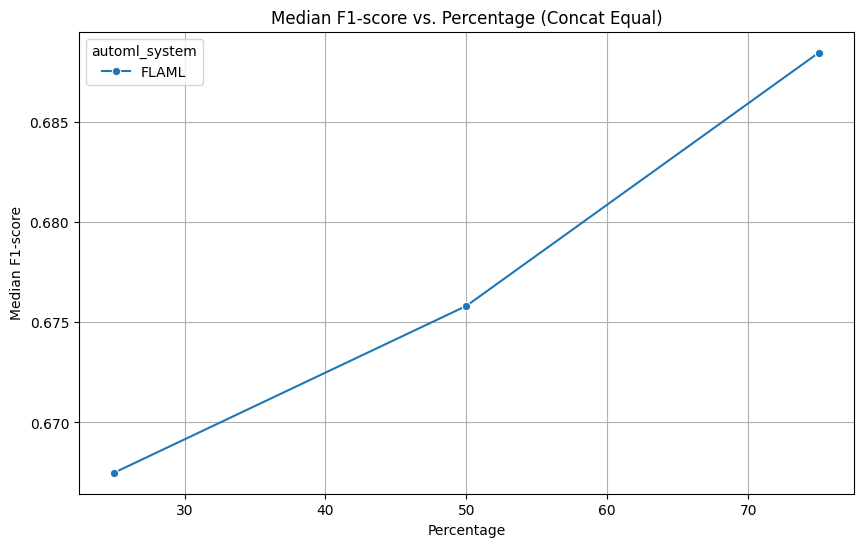

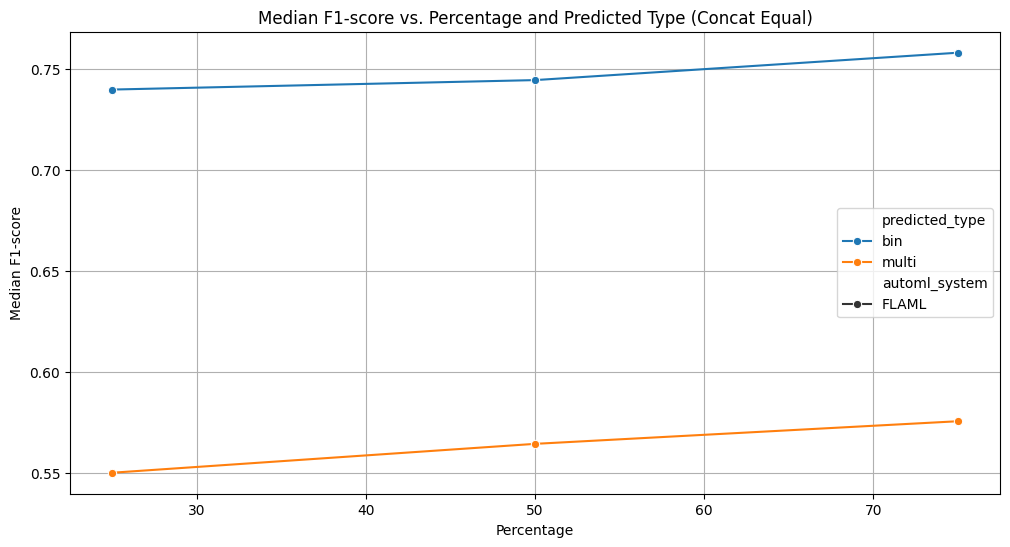

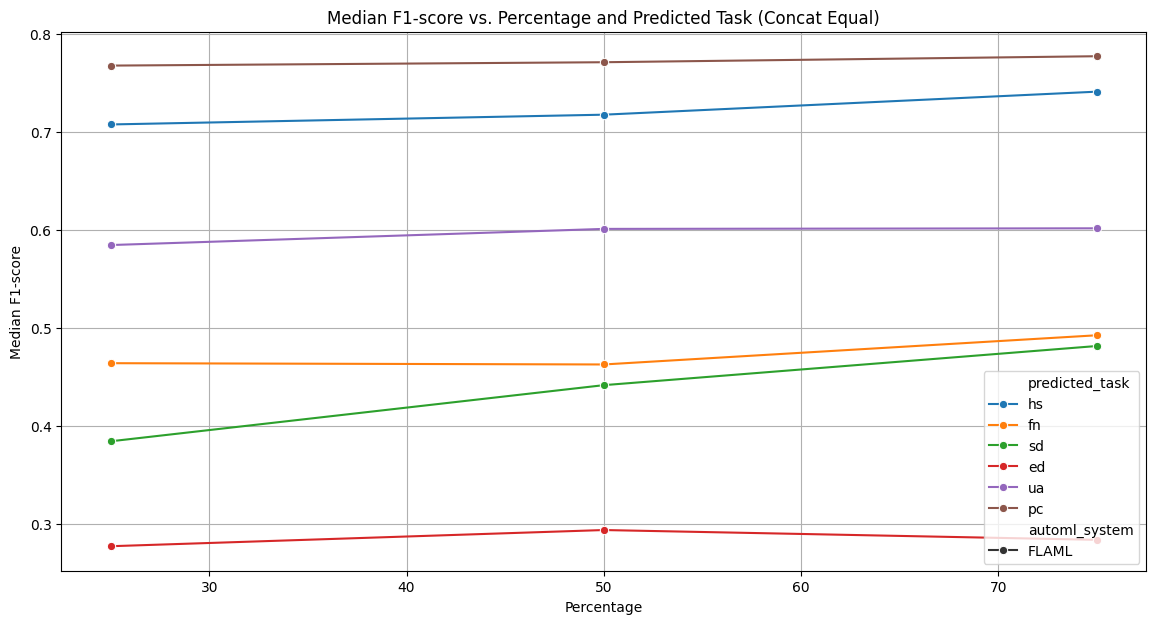

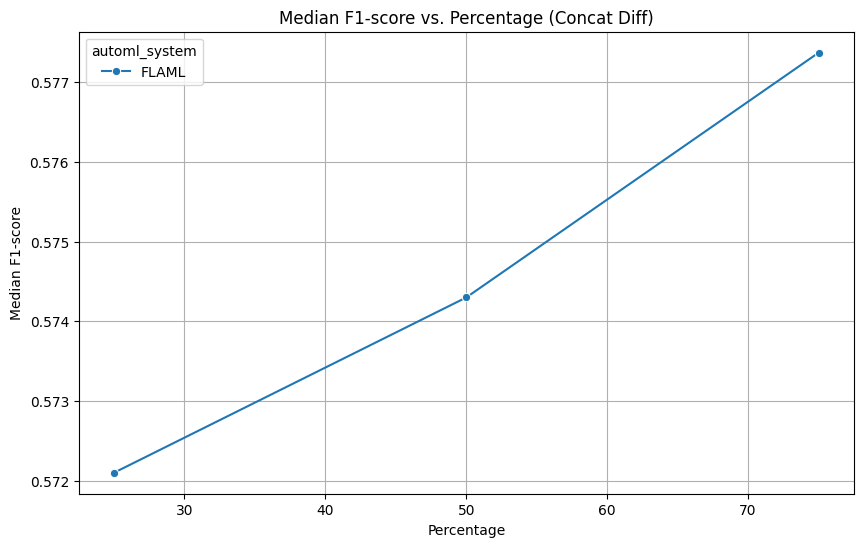

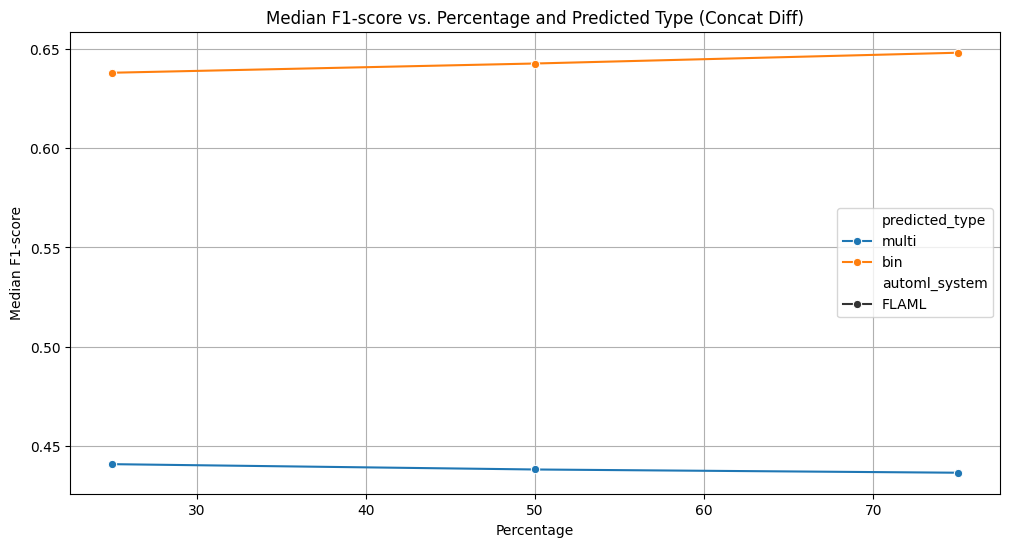

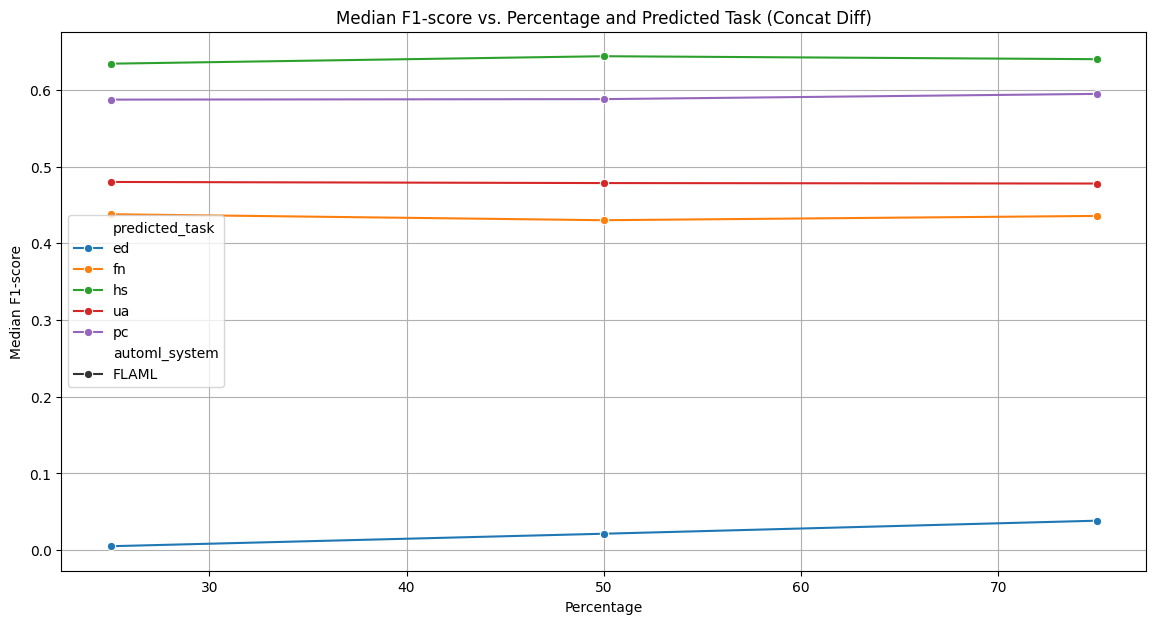

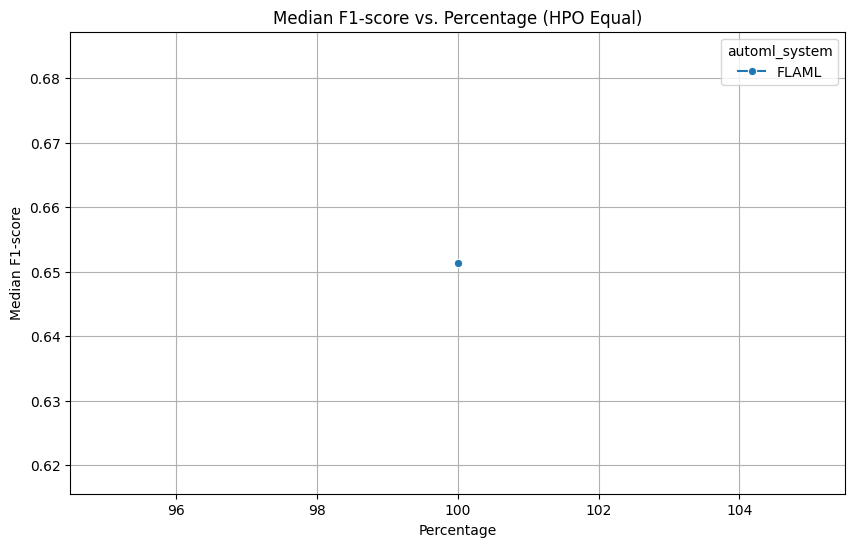

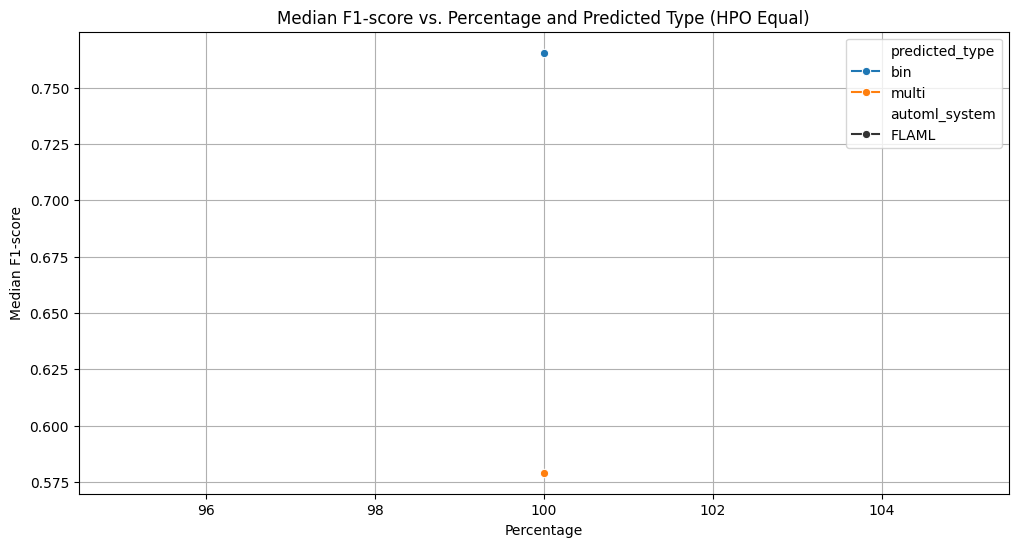

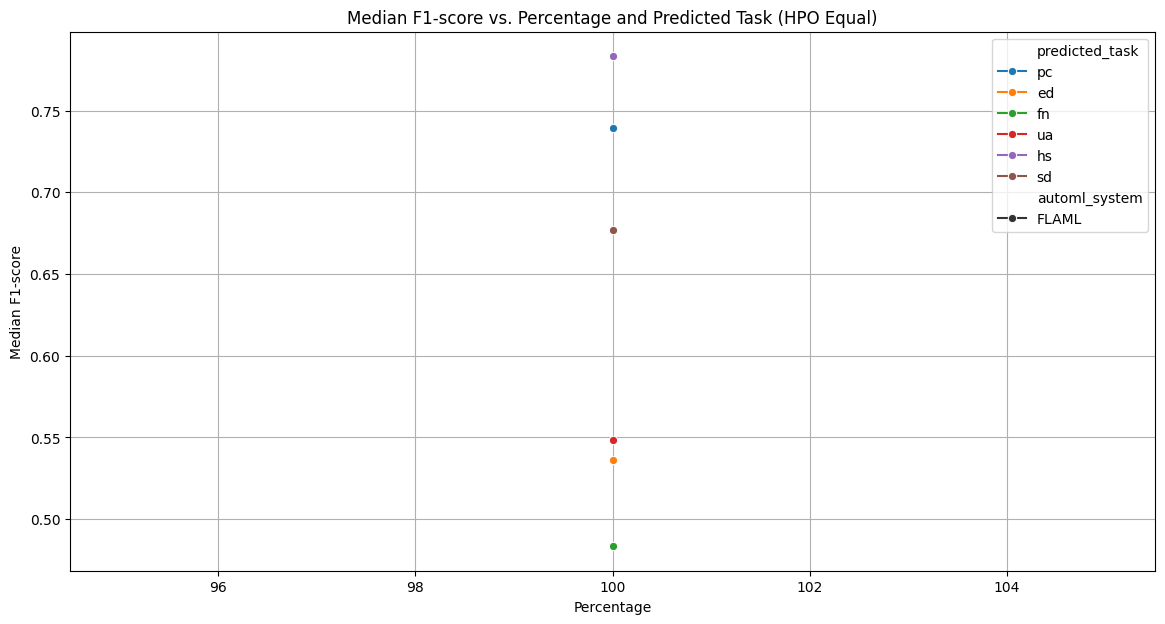

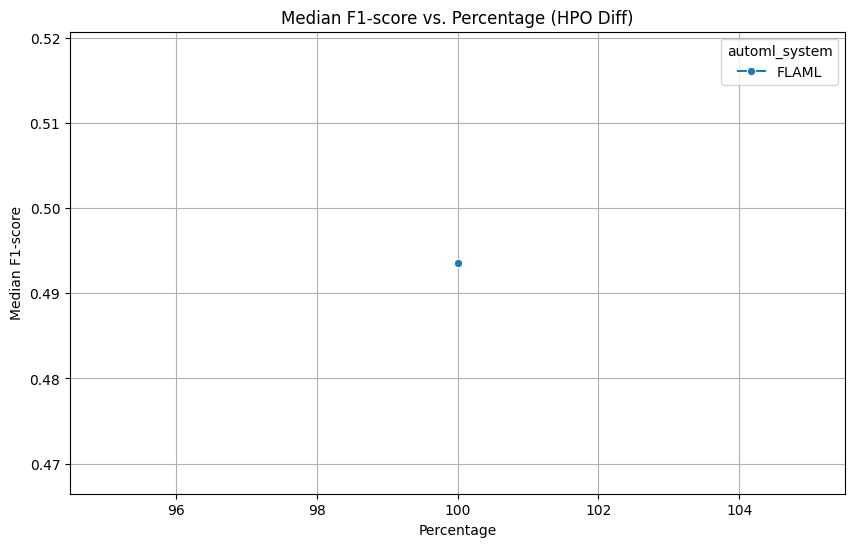

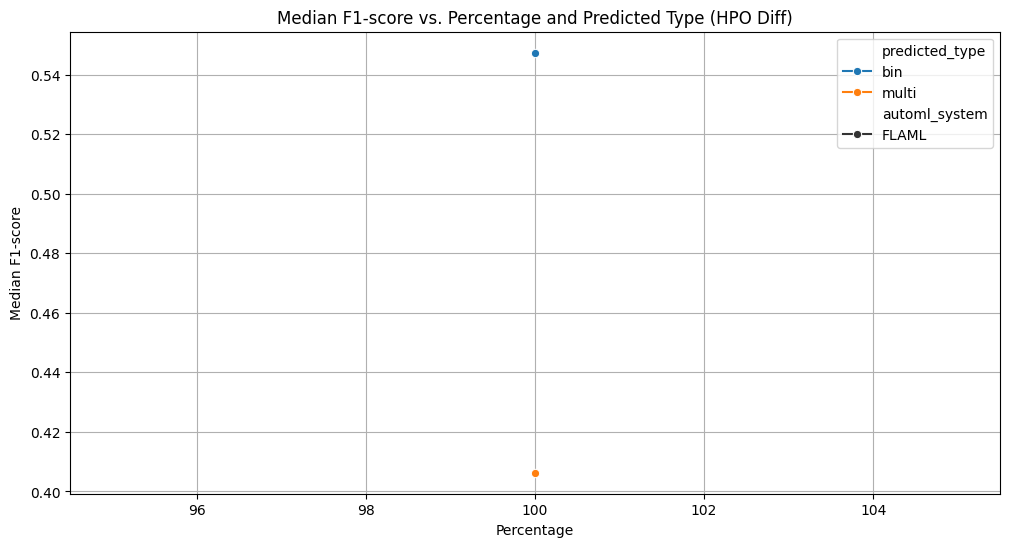

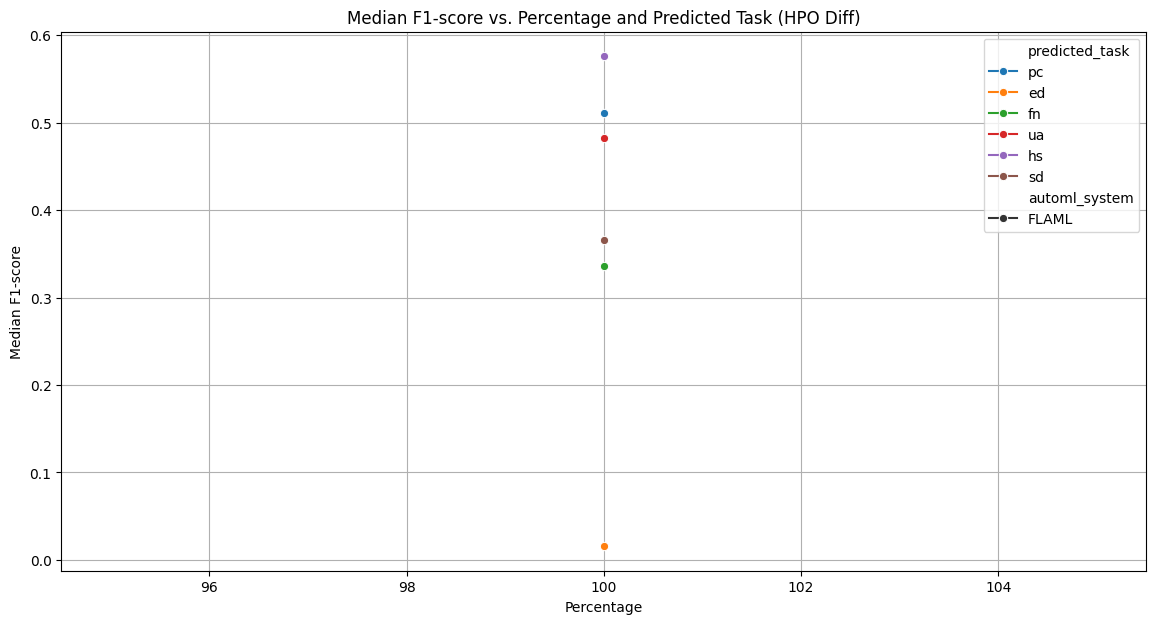


--- Monotonicity Analysis for Concat Equal ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for Concat Diff ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for HPO Equal ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for HPO Diff ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Label Imbalance Ins

/tmp/ipython-input-1745362849.py:257: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")
/tmp/ipython-input-1745362849.py:274: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])
/tmp/ipython-input-1745362849.py:293: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")
/tmp/ipython-input-1745362849.py:310: FutureWarning: The default of observed=Fals

hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.015559
               fn             0.348087
               hs             0.603971
               ua             0.482330
(0.05, 0.1]    hs             0.309372
               pc             0.237264
(0.1, 0.2]     hs             0.557018
               pc             0.381163
               ua             0.510810
(0.2, 0.3]     fn             0.268231
               hs             0.883704
               pc             0.413453
(0.3, 0.5]     fn             0.230248
               hs             0.460411
(0.6, 0.7]     sd             0.352000
(0.7, 0.8]     hs             0.654601
(0.8, 0.9]     fn             0.500000
               hs             0.435168
               sd             0.378667
(0.9, 1.0]     fn             0.467796
               hs             0.648241
               pc             0.746637
               ua             0.392863

In [ ]:
!pip install matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# --- Visualizing Concat Equal ---

# Median F1-score by Percentage for Concat Equal
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None  # Hide error bars for median
)
plt.title("Median F1-score vs. Percentage (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for Concat Equal
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for Concat Equal
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing Concat Diff ---

# Median F1-score by Percentage for Concat Diff
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for Concat Diff
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for Concat Diff
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing HPO Equal ---

# Median F1-score by Percentage for HPO Equal
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for HPO Equal
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for HPO Equal
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing HPO Diff ---

# Median F1-score by Percentage for HPO Diff
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for HPO Diff
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for HPO Diff
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

automl_system = system_map[system]

# Insight regarding monotonicity for Concat Equal
print("\n--- Monotonicity Analysis for Concat Equal ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_concat_equal = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_concat_equal.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for Concat Diff
print("\n--- Monotonicity Analysis for Concat Diff ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_concat_diff = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_concat_diff.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for HPO Equal
print("\n--- Monotonicity Analysis for HPO Equal ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_hpo_equal = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_hpo_equal.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for HPO Diff
print("\n--- Monotonicity Analysis for HPO Diff ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_hpo_diff = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_hpo_diff.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))


# Insight regarding label imbalance for Concat Equal (Percentage 100)
print("\n--- Label Imbalance Insight for Concat Equal (Percentage 100) ---")
concat_equal_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (Concat Equal, 100%):")
print(concat_equal_imbalance_analysis)

concat_equal_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (Concat Equal, 100%):")
print(concat_equal_imbalance_task_analysis)

# Insight regarding label imbalance for Concat Diff (Percentage 100)
print("\n--- Label Imbalance Insight for Concat Diff (Percentage 100) ---")
concat_diff_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (Concat Diff, 100%):")
print(concat_diff_imbalance_analysis)

concat_diff_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (Concat Diff, 100%):")
print(concat_diff_imbalance_task_analysis)


# Insight regarding label imbalance for HPO Equal (Percentage 100)
print("\n--- Label Imbalance Insight for HPO Equal (Percentage 100) ---")
hpo_equal_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (HPO Equal, 100%):")
print(hpo_equal_imbalance_analysis)

hpo_equal_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (HPO Equal, 100%):")
print(hpo_equal_imbalance_task_analysis)

# Insight regarding label imbalance for HPO Diff (Percentage 100)
print("\n--- Label Imbalance Insight for HPO Diff (Percentage 100) ---")
hpo_diff_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (HPO Diff, 100%):")
print(hpo_diff_imbalance_analysis)

hpo_diff_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (HPO Diff, 100%):")
hpo_diff_imbalance_task_analysis
